# Workshop 2 — Red neuronal profunda desde cero: resistencia del concreto

**Curso:** ST1613 Applied Machine Learning — EAFIT
**Competencia:** [Concrete Strength Regression (Kaggle)](https://www.kaggle.com/competitions/concrete-strength-regression)
**Framework:** PyTorch

**Objetivo:** construir, entrenar y evaluar una red neuronal *fully connected* (MLP) implementada desde cero en PyTorch para predecir la **resistencia a la compresión del concreto** (`csMPa`, en MPa) a partir de su composición y edad. La métrica oficial de la competencia es el **MSE** (menor es mejor).

## Índice

0. Setup
1. Parte 1 — EDA de reconocimiento
2. Parte 2 — Preprocesamiento
3. Parte 3 — `Dataset` y `DataLoader`
4. Parte 4 — Arquitectura de la red
5. Parte 5 — Entrenamiento y validación
6. Parte 6 — Experimentación
7. Parte 7 — Predicción y submission en Kaggle
8. Conclusiones

## 0. Setup

Importamos las librerías, fijamos semillas para que los resultados sean reproducibles y definimos el `device`. Con 721 filas la CPU es suficiente, pero el código usa `cuda` si está disponible.

In [1]:
import os
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim import Adam

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| device:", device)

DATA_DIR = "../data"
FIG_DIR = "../reports/figures"
SUB_DIR = "../submissions"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(SUB_DIR, exist_ok=True)

ID_COL, TARGET = "Row ID", "csMPa"

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 2)

PyTorch: 2.11.0+cpu | device: cpu


## 1. Parte 1 — EDA de reconocimiento

Antes de modelar exploramos los datos para entender su estructura y justificar las decisiones de preprocesamiento.

### 1.1 Dimensiones, tipos de datos y primeras filas

In [2]:
train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")
sample_sub = pd.read_csv(f"{DATA_DIR}/sample_submission.csv")

print("train:", train.shape, "| test:", test.shape, "| sample_submission:", sample_sub.shape)
print("Columnas:", list(train.columns))

train: (721, 10) | test: (309, 9) | sample_submission: (10, 2)
Columnas: ['Row ID', 'cement', 'slag', 'flyash', 'water', 'superplasticizer', 'coarseaggregate', 'fineaggregate', 'age', 'csMPa']


In [3]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 721 entries, 0 to 720
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Row ID            721 non-null    int64  
 1   cement            721 non-null    float64
 2   slag              721 non-null    float64
 3   flyash            721 non-null    float64
 4   water             721 non-null    float64
 5   superplasticizer  721 non-null    float64
 6   coarseaggregate   721 non-null    float64
 7   fineaggregate     721 non-null    float64
 8   age               721 non-null    int64  
 9   csMPa             721 non-null    float64
dtypes: float64(8), int64(2)
memory usage: 56.5 KB


In [4]:
test.info()

<class 'pandas.DataFrame'>
RangeIndex: 309 entries, 0 to 308
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Row ID            309 non-null    int64  
 1   cement            309 non-null    float64
 2   slag              309 non-null    float64
 3   flyash            309 non-null    float64
 4   water             309 non-null    float64
 5   superplasticizer  309 non-null    float64
 6   coarseaggregate   309 non-null    float64
 7   fineaggregate     309 non-null    float64
 8   age               309 non-null    int64  
dtypes: float64(7), int64(2)
memory usage: 21.9 KB


In [5]:
train.head()

,Row ID,cement,slag,flyash,water,superplasticizer,coarseaggregate,fineaggregate,age,csMPa
0,0,184.0,86.0,190.0,213.0,6.0,923.0,623.0,28,22.93
1,1,313.3,145.0,0.0,178.5,8.0,1001.9,688.7,28,41.05
2,2,387.0,20.0,94.0,157.0,13.9,938.0,845.0,7,45.90
3,3,162.0,214.0,164.0,202.0,10.0,820.0,680.0,28,30.65
4,4,252.3,0.0,98.8,146.3,14.2,987.8,889.0,14,42.29


In [6]:
test.head()

,Row ID,cement,slag,flyash,water,superplasticizer,coarseaggregate,fineaggregate,age
0,721,167.4,129.9,128.6,175.5,7.8,1006.3,746.6,14
1,722,255.5,170.3,0.0,185.7,0.0,1026.6,724.3,28
2,723,246.8,0.0,125.1,143.3,12.0,1086.8,800.9,3
3,724,318.8,212.5,0.0,155.7,14.3,852.1,880.4,28
4,725,218.9,0.0,124.1,158.5,11.3,1078.7,794.9,56


In [7]:
sample_sub.head(10)

,Row ID,csMPa
0,136,3.0
1,141,4.0
2,164,5.0
3,262,6.0
4,247,7.0
5,51,8.0
6,10,9.0
7,225,10.0
8,2,11.0
9,158,12.0


**Observaciones:**
- `train` tiene **721 filas × 10 columnas** (`Row ID`, 8 predictores y el target `csMPa`) y `test` tiene **309 filas × 9 columnas** (sin target). Los nombres reales difieren de los del enunciado: `slag`, `flyash`, `superplasticizer`, `coarseaggregate`, `fineaggregate`, `age`, `csMPa`.
- Todos los predictores son `float64`, salvo `age` (`int64`).
- `sample_submission.csv` **solo trae 10 filas ilustrativas**, y sus `Row ID` son del rango de train. La submission real debe tener una fila por cada registro de `test.csv` (309 filas, `Row ID` 721–1029) con las columnas `Row ID, csMPa`.

### 1.2 Estadísticas descriptivas

In [8]:
FEATURES = [c for c in train.columns if c not in (ID_COL, TARGET)]
train[FEATURES + [TARGET]].describe().T

,count,mean,std,min,25%,50%,75%,max
cement,721.0,280.63,103.11,102.00,194.70,273.00,359.00,540.0
slag,721.0,74.74,85.70,0.00,0.00,24.00,142.80,359.4
flyash,721.0,54.87,63.33,0.00,0.00,0.00,118.20,200.0
water,721.0,181.03,21.57,121.80,164.90,184.00,192.00,247.0
superplasticizer,721.0,6.50,6.00,0.00,0.00,6.90,10.60,32.2
coarseaggregate,721.0,971.40,76.52,801.00,932.00,967.00,1028.40,1134.3
fineaggregate,721.0,775.13,78.89,594.00,734.00,780.00,825.00,992.6
age,721.0,44.95,60.43,1.00,14.00,28.00,56.00,365.0
csMPa,721.0,36.16,17.20,2.33,23.35,34.57,47.71,82.6


In [9]:
test[FEATURES].describe().T

,count,mean,std,min,25%,50%,75%,max
cement,309.0,282.42,107.85,108.3,190.3,272.8,342.0,540.0
slag,309.0,71.93,87.73,0.0,0.0,17.5,143.0,359.4
flyash,309.0,52.59,65.59,0.0,0.0,0.0,118.3,200.1
water,309.0,182.82,20.82,121.8,168.0,185.7,192.9,246.9
superplasticizer,309.0,5.51,5.87,0.0,0.0,5.8,9.7,32.2
coarseaggregate,309.0,976.46,80.57,801.0,932.0,971.8,1040.0,1145.0
fineaggregate,309.0,769.97,83.13,594.0,728.9,778.0,822.0,945.0
age,309.0,47.32,69.22,1.0,7.0,28.0,56.0,365.0


**Observaciones:**
- Las escalas son muy distintas: `superplasticizer` va de 0 a 32, mientras que `coarseaggregate` va de 801 a 1134 y `fineaggregate` de 594 a 993. Sin escalar, las variables grandes dominarían los gradientes de la red.
- `slag`, `flyash` y `superplasticizer` tienen mínimo 0 y mediana baja o nula: muchas mezclas no usan esos componentes.
- `age` tiene media 45 pero mediana 28 y máximo 365, señal de una cola larga a la derecha.
- El target `csMPa` va de 2.3 a 82.6 MPa (media 36.2, desviación 17.2).
- Las estadísticas de `test` son muy parecidas a las de `train` (lo verificamos formalmente en 1.8).

### 1.3 Valores faltantes y filas duplicadas

In [10]:
missing = pd.DataFrame({"train": train.isna().sum(), "test": test.isna().sum()})
print("Total faltantes -> train:", train.isna().sum().sum(), "| test:", test.isna().sum().sum())
missing.T

Total faltantes -> train: 0 | test: 0


,Row ID,age,cement,coarseaggregate,csMPa,fineaggregate,flyash,slag,superplasticizer,water
train,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
test,0.0,0.0,0.0,0.0,NaN,0.0,0.0,0.0,0.0,0.0


In [11]:
# Excluimos Row ID: dos filas con distinto ID pero misma mezcla y resultado son duplicados reales.
dup_exact = train.duplicated(subset=FEATURES + [TARGET]).sum()
dup_feat = train.duplicated(subset=FEATURES).sum()
print(f"Filas duplicadas exactas (features + target): {dup_exact}")
print(f"Filas con features repetidas (sin contar target): {dup_feat}")

# Mezclas repetidas con target distinto: mismo concreto, distinto resultado de laboratorio.
grp = train.groupby(FEATURES)[TARGET].agg(["count", "nunique", "min", "max", "std"])
conflict = grp[(grp["count"] > 1) & (grp["nunique"] > 1)].reset_index()
print(f"Mezclas repetidas con target distinto: {len(conflict)}")
conflict.sort_values("std", ascending=False)

Filas duplicadas exactas (features + target): 16
Filas con features repetidas (sin contar target): 26
Mezclas repetidas con target distinto: 7


,cement,slag,flyash,water,superplasticizer,coarseaggregate,fineaggregate,age,count,nunique,min,max,std
2,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,3,2,22.90,55.90,19.05
4,446.0,24.0,79.0,162.0,11.6,967.0,712.0,7,2,2,38.02,52.01,9.89
3,446.0,24.0,79.0,162.0,11.6,967.0,712.0,3,3,3,23.35,35.36,6.51
5,446.0,24.0,79.0,162.0,11.6,967.0,712.0,28,3,3,44.42,57.03,6.31
6,446.0,24.0,79.0,162.0,11.6,967.0,712.0,56,3,3,55.25,61.07,3.14
1,359.0,19.0,141.0,154.0,10.9,942.0,801.0,28,2,2,59.49,62.94,2.44
0,359.0,19.0,141.0,154.0,10.9,942.0,801.0,3,2,2,23.64,25.12,1.05


In [12]:
n_test_in_train = test[FEATURES].merge(train[FEATURES].drop_duplicates(), how="inner").shape[0]
print(f"Filas de test cuyas features aparecen tal cual en train: {n_test_in_train}")
print(f"Duplicados dentro de test: {test.duplicated(subset=FEATURES).sum()}")

Filas de test cuyas features aparecen tal cual en train: 11
Duplicados dentro de test: 4


**Observaciones:**
- **No hay valores faltantes** ni en `train` ni en `test`, como dice la documentación. No hace falta imputar.
- Hay **16 filas duplicadas exactas** (misma mezcla, edad y resistencia) y **26 filas** que repiten una combinación de predictores ya vista. En **7 mezclas repetidas el target es distinto**; la diferencia llega a 33 MPa (22.9 vs 55.9) para la misma mezcla a 7 días. Esto refleja la **variabilidad propia del ensayo de laboratorio**: es ruido irreducible que ningún modelo puede eliminar.
- **Implicación para la validación:** si una misma mezcla queda en entrenamiento y en validación a la vez, la red "la recuerda" y el error de validación sale optimista. En la Parte 2 lo manejaremos agrupando las mezclas idénticas en la partición (`GroupKFold` / split por grupo).
- 11 filas de `test` tienen predictores idénticos a filas de `train`. No las explotamos manualmente: el modelo debe generalizar.

### 1.4 Tipos de variables: numéricas, categóricas y columnas a excluir

In [13]:
num_cols = train[FEATURES].select_dtypes(include="number").columns.tolist()
cat_cols = train[FEATURES].select_dtypes(exclude="number").columns.tolist()
print("Numéricas :", num_cols)
print("Categóricas:", cat_cols if cat_cols else "ninguna")

summary = pd.DataFrame({
    "dtype": train[FEATURES].dtypes.astype(str),
    "n_unicos": train[FEATURES].nunique(),
    "pct_ceros": (train[FEATURES] == 0).mean().mul(100).round(1),
})
summary

Numéricas : ['cement', 'slag', 'flyash', 'water', 'superplasticizer', 'coarseaggregate', 'fineaggregate', 'age']
Categóricas: ninguna


,dtype,n_unicos,pct_ceros
cement,float64,245,0.0
slag,float64,153,44.7
flyash,float64,131,53.7
water,float64,174,0.0
superplasticizer,float64,105,34.5
coarseaggregate,float64,242,0.0
fineaggregate,float64,259,0.0
age,int64,14,0.0


In [14]:
# Row ID es solo un identificador: comprobamos que no tiene relación con el target.
r, p = stats.pearsonr(train[ID_COL], train[TARGET])
print(f"Correlación Row ID vs {TARGET}: r = {r:.3f} (p = {p:.2f})")

Correlación Row ID vs csMPa: r = -0.019 (p = 0.61)


**Observaciones:**
- Las **8 variables predictoras son numéricas continuas** (cantidades en kg/m³ y edad en días). **No hay variables categóricas, así que no se requiere encoding.**
- `age` solo toma **14 valores distintos**, por lo que podría tratarse como categórica. Sin embargo es una magnitud ordenada (más días → más resistencia), y tratarla como numérica conserva esa relación y permite interpolar edades intermedias. La trataremos como **numérica** (transformada con `log1p`).
- `Row ID` es un identificador secuencial sin relación con el target (r = −0.02, p = 0.61), así que **se excluye de los predictores**. Solo se usa para construir la submission.

### 1.5 Distribución de la variable objetivo

Asimetría (skew): 0.391 | curtosis: -0.445
Límites IQR: [-13.19, 84.25] MPa -> outliers: 0


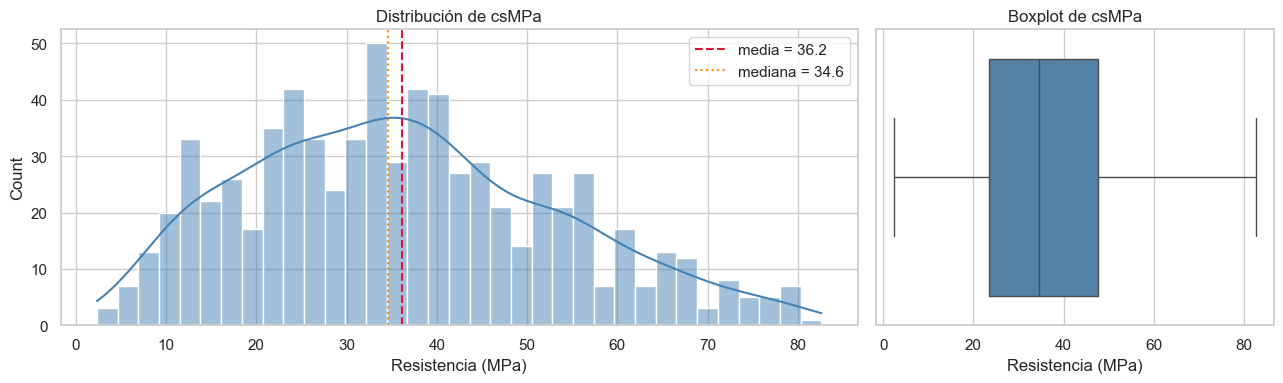

,Row ID,cement,slag,flyash,water,superplasticizer,coarseaggregate,fineaggregate,age,csMPa


In [15]:
y = train[TARGET]
q1, q3 = y.quantile([0.25, 0.75])
iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = train[(y < lo) | (y > hi)]

print(f"Asimetría (skew): {y.skew():.3f} | curtosis: {y.kurt():.3f}")
print(f"Límites IQR: [{lo:.2f}, {hi:.2f}] MPa -> outliers: {len(outliers)}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [2, 1]})
sns.histplot(y, bins=35, kde=True, ax=axes[0], color="steelblue")
axes[0].axvline(y.mean(), color="crimson", ls="--", label=f"media = {y.mean():.1f}")
axes[0].axvline(y.median(), color="darkorange", ls=":", label=f"mediana = {y.median():.1f}")
axes[0].set(title="Distribución de csMPa", xlabel="Resistencia (MPa)")
axes[0].legend()
sns.boxplot(x=y, ax=axes[1], color="steelblue")
axes[1].set(title="Boxplot de csMPa", xlabel="Resistencia (MPa)")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/01_target_distribution.png", dpi=120, bbox_inches="tight")
plt.show()

outliers.sort_values(TARGET)

**Observaciones:**
- La distribución de `csMPa` es **unimodal y ligeramente asimétrica a la derecha** (skew = 0.39; media 36.2 > mediana 34.6), con colas más livianas que una normal (curtosis = −0.45).
- Con el criterio IQR **no hay outliers** (límites [−13.2, 84.3] MPa; el máximo es 82.6). No hace falta eliminar ni recortar valores del target.
- La asimetría es leve, así que no transformaremos el target con `log`. Sí lo **estandarizaremos** (`StandardScaler`) para estabilizar el entrenamiento, e invertiremos la transformación antes de calcular métricas y generar la submission.

### 1.6 Distribución de cada predictor

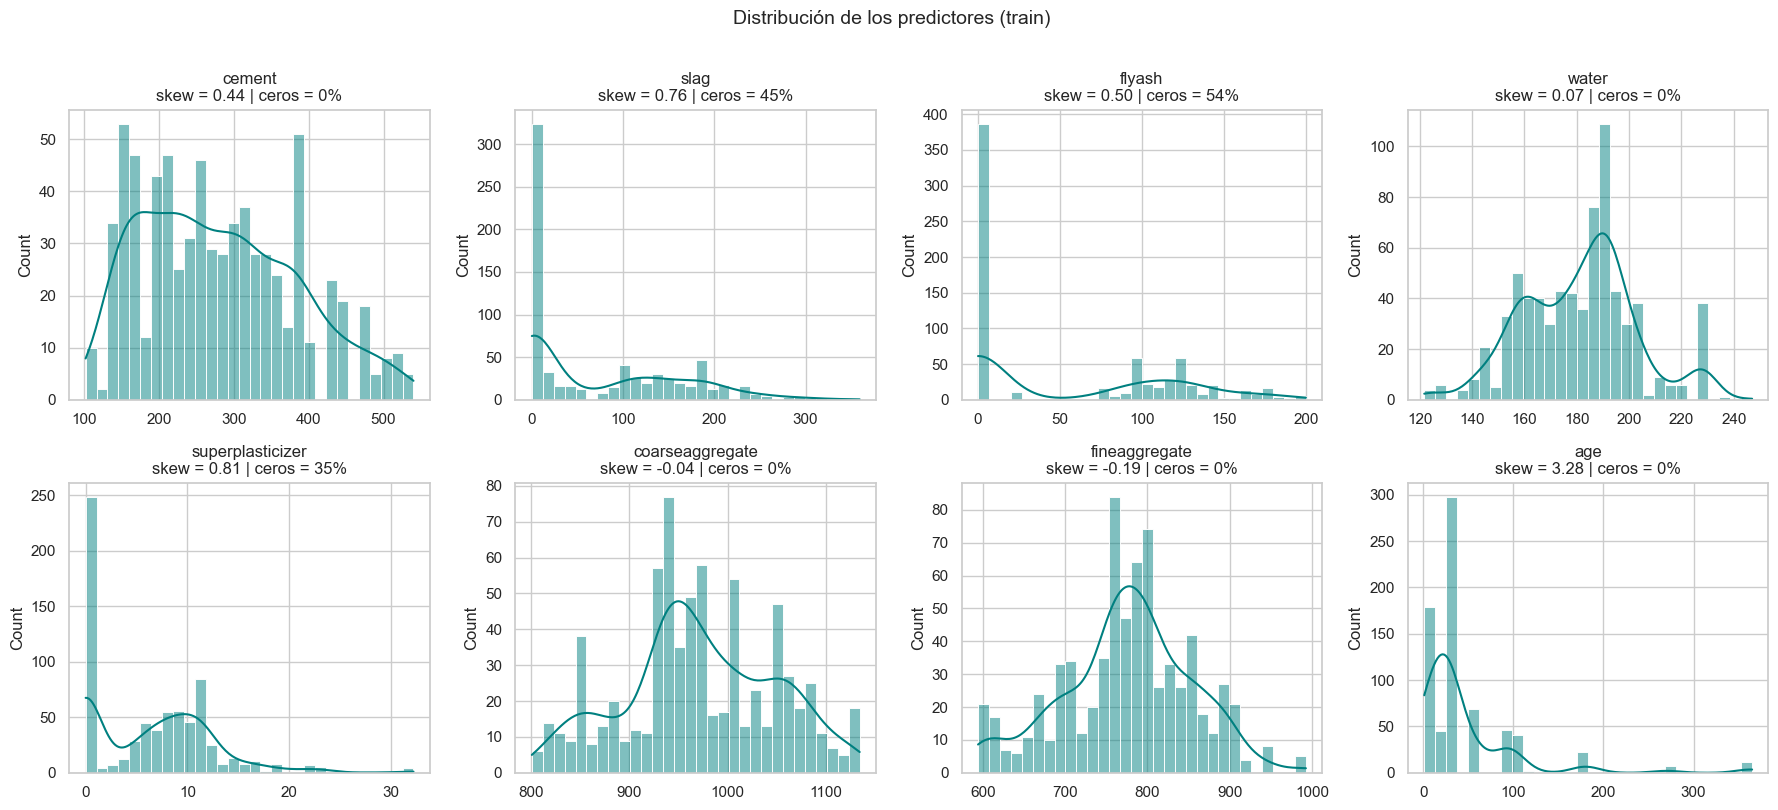

In [16]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.histplot(train[col], bins=30, kde=True, ax=ax, color="teal")
    ax.set_title(f"{col}\nskew = {train[col].skew():.2f} | ceros = {(train[col] == 0).mean():.0%}")
    ax.set_xlabel("")
plt.suptitle("Distribución de los predictores (train)", y=1.01, fontsize=14)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/02_feature_distributions.png", dpi=120, bbox_inches="tight")
plt.show()

In [17]:
skew_zero = pd.DataFrame({
    "skew": train[FEATURES].skew(),
    "pct_ceros": (train[FEATURES] == 0).mean().mul(100),
    "min": train[FEATURES].min(),
    "max": train[FEATURES].max(),
}).sort_values("skew", ascending=False)
skew_zero

,skew,pct_ceros,min,max
age,3.28,0.00,1.0,365.0
superplasticizer,0.81,34.54,0.0,32.2
slag,0.76,44.66,0.0,359.4
flyash,0.50,53.68,0.0,200.0
cement,0.44,0.00,102.0,540.0
water,0.07,0.00,121.8,247.0
coarseaggregate,-0.04,0.00,801.0,1134.3
fineaggregate,-0.19,0.00,594.0,992.6


Valores distintos de age: 14
Top 4 (28, 3, 7, 56 días) concentran el 76% de las filas


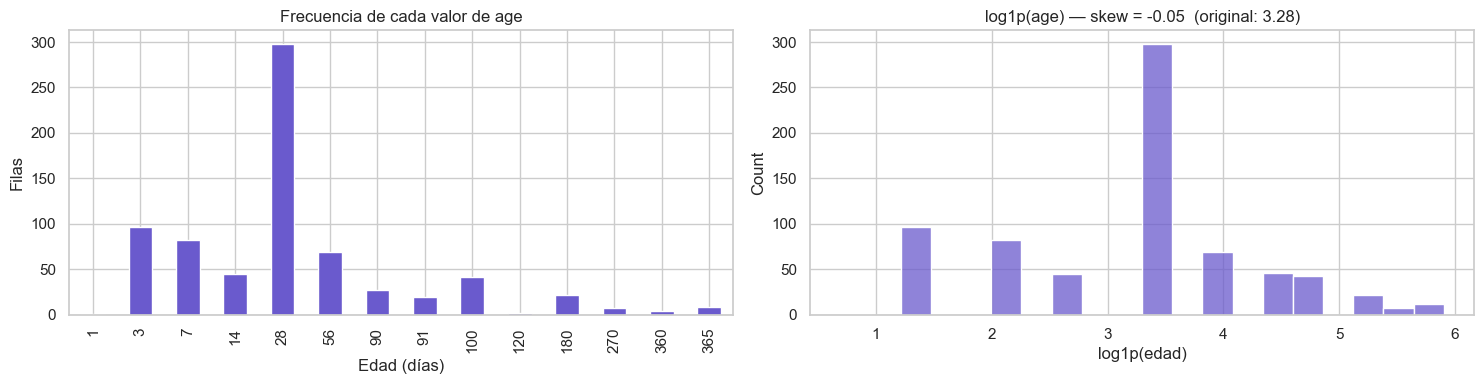

In [18]:
# Age: pocos valores distintos y muy concentrados.
age_counts = train["age"].value_counts().sort_index()
print("Valores distintos de age:", train["age"].nunique())
print(f"Top 4 (28, 3, 7, 56 días) concentran el {train['age'].isin([28, 3, 7, 56]).mean():.0%} de las filas")

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
age_counts.plot.bar(ax=axes[0], color="slateblue")
axes[0].set(title="Frecuencia de cada valor de age", xlabel="Edad (días)", ylabel="Filas")
sns.histplot(np.log1p(train["age"]), bins=20, ax=axes[1], color="slateblue")
axes[1].set(title=f"log1p(age) — skew = {np.log1p(train['age']).skew():.2f}  (original: {train['age'].skew():.2f})",
            xlabel="log1p(edad)")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/03_age.png", dpi=120, bbox_inches="tight")
plt.show()

**Observaciones:**
- **Muchos ceros:** `flyash` (54 %), `slag` (45 %) y `superplasticizer` (35 %). Estas variables son una mezcla de "no se usa el componente" (cero) y "cantidad usada" (distribución continua). Por eso crearemos **indicadores binarios de presencia** (`has_slag`, `has_flyash`, `has_sp`).
- **`age` es la variable más asimétrica** (skew = 3.28) y está muy concentrada: 28, 3, 7 y 56 días suman el 76 % de las filas. Con `log1p(age)` la asimetría baja a −0.05, lo que la hace más adecuada como entrada de la red.
- `water`, `coarseaggregate` y `fineaggregate` son aproximadamente simétricas y no requieren transformación más allá del escalamiento.

### 1.7 Correlaciones y relación de cada predictor con el objetivo

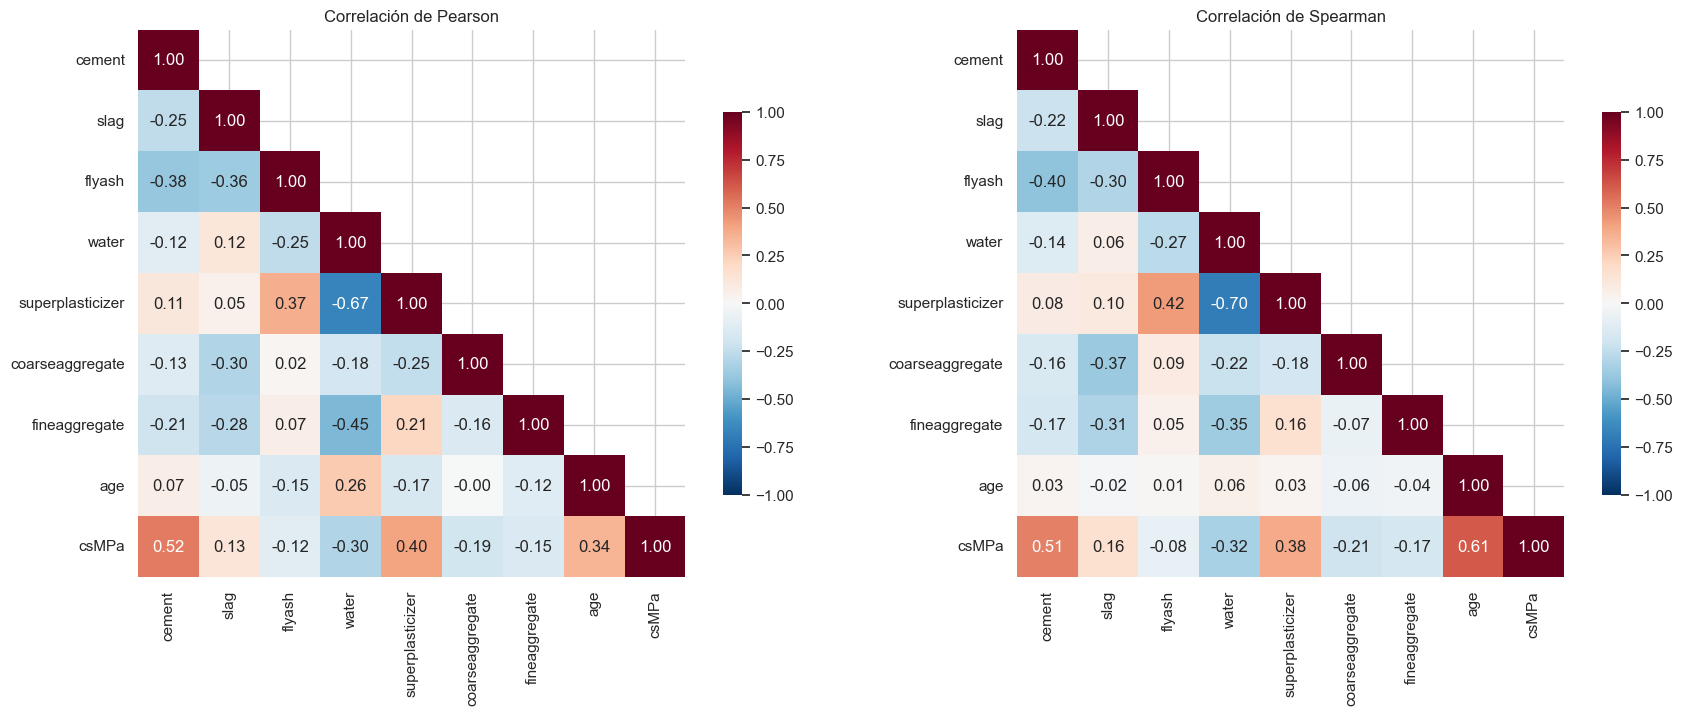

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, method in zip(axes, ["pearson", "spearman"]):
    corr = train[FEATURES + [TARGET]].corr(method=method)
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
    sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
                vmin=-1, vmax=1, square=True, cbar_kws={"shrink": 0.7}, ax=ax)
    ax.set_title(f"Correlación de {method.capitalize()}")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/04_correlations.png", dpi=120, bbox_inches="tight")
plt.show()

In [20]:
corr_target = pd.DataFrame({
    "pearson": train[FEATURES].corrwith(train[TARGET]),
    "spearman": train[FEATURES].corrwith(train[TARGET], method="spearman"),
}).sort_values("pearson", key=abs, ascending=False)
corr_target

,pearson,spearman
cement,0.52,0.51
superplasticizer,0.40,0.38
age,0.34,0.61
water,-0.30,-0.32
coarseaggregate,-0.19,-0.21
fineaggregate,-0.15,-0.17
slag,0.13,0.16
flyash,-0.12,-0.08


**Observaciones:**
- Los predictores con mayor correlación lineal con la resistencia son `cement` (+0.52), `superplasticizer` (+0.40), `age` (+0.34) y `water` (−0.30). Los agregados, `slag` y `flyash` tienen correlaciones débiles por sí solos.
- Para `age` la correlación de **Spearman (0.61) es mucho mayor que la de Pearson (0.34)**: la relación es **monótona pero no lineal**.
- Entre predictores hay correlaciones moderadas (p. ej. `water` vs `superplasticizer` = −0.67). No es un problema serio para una red neuronal, pero confirma que las variables interactúan.

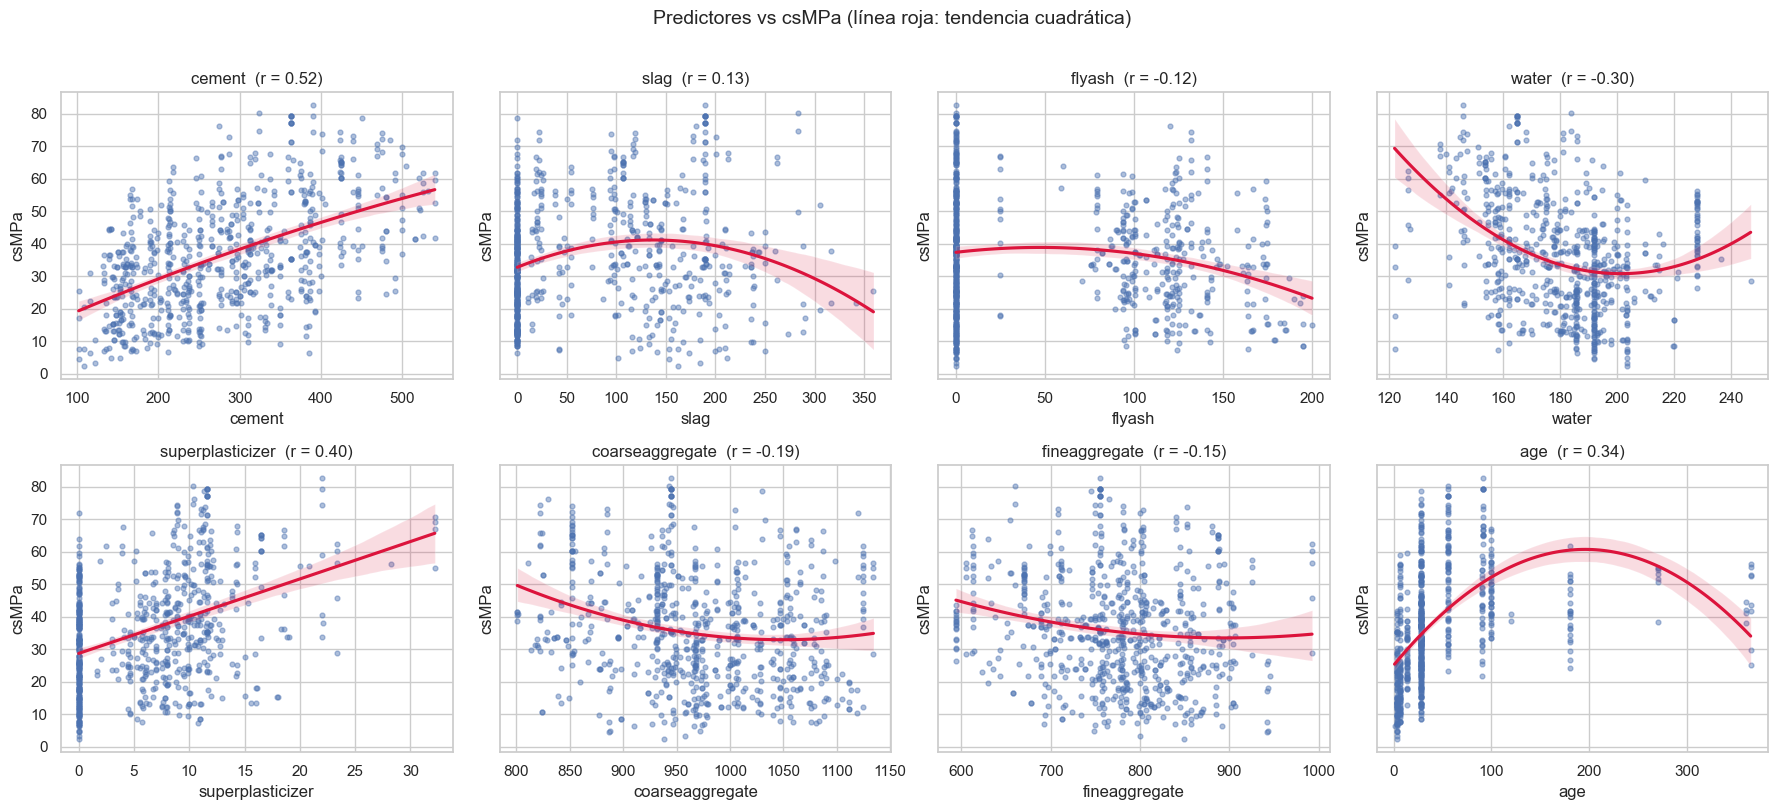

In [21]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharey=True)
for ax, col in zip(axes.ravel(), FEATURES):
    sns.regplot(data=train, x=col, y=TARGET, ax=ax, order=2,
                scatter_kws={"s": 12, "alpha": 0.45}, line_kws={"color": "crimson"})
    ax.set_title(f"{col}  (r = {train[col].corr(train[TARGET]):.2f})")
plt.suptitle("Predictores vs csMPa (línea roja: tendencia cuadrática)", y=1.01, fontsize=14)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/05_scatter_vs_target.png", dpi=120, bbox_inches="tight")
plt.show()

**Observaciones:**
- Ningún predictor por sí solo explica bien la resistencia: hay mucha dispersión vertical en todos los gráficos. El target depende de **combinaciones** de variables, justo lo que una red neuronal puede modelar.
- `cement` y `superplasticizer` muestran tendencias crecientes claras; `water` una tendencia decreciente.
- En `slag`, `flyash` y `superplasticizer` se ve la columna de puntos en 0 que comentamos antes.
- En `age` la curva cuadrática cae al final, pero es un artefacto del ajuste polinómico con pocos puntos en edades altas. La relación real es creciente y se satura, como se ve en la siguiente figura.

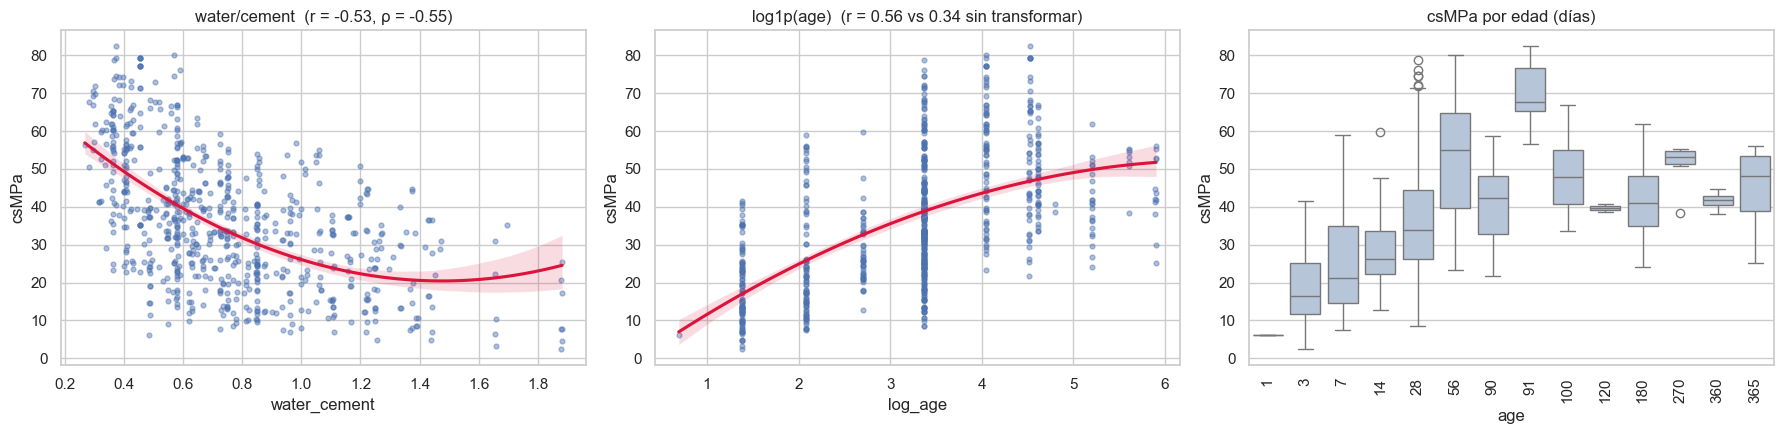

In [22]:
# Variables derivadas que motivan el feature engineering de la Parte 2.
eda = train.copy()
eda["water_cement"] = eda["water"] / eda["cement"]
eda["log_age"] = np.log1p(eda["age"])

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
sns.regplot(data=eda, x="water_cement", y=TARGET, order=2, ax=axes[0],
            scatter_kws={"s": 12, "alpha": 0.45}, line_kws={"color": "crimson"})
axes[0].set_title(f"water/cement  (r = {eda['water_cement'].corr(eda[TARGET]):.2f}, "
                  f"ρ = {eda['water_cement'].corr(eda[TARGET], method='spearman'):.2f})")
sns.regplot(data=eda, x="log_age", y=TARGET, order=2, ax=axes[1],
            scatter_kws={"s": 12, "alpha": 0.45}, line_kws={"color": "crimson"})
axes[1].set_title(f"log1p(age)  (r = {eda['log_age'].corr(eda[TARGET]):.2f} vs "
                  f"{eda['age'].corr(eda[TARGET]):.2f} sin transformar)")
sns.boxplot(data=eda, x="age", y=TARGET, ax=axes[2], color="lightsteelblue")
axes[2].set_title("csMPa por edad (días)")
axes[2].tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/06_engineered_features.png", dpi=120, bbox_inches="tight")
plt.show()

**Observaciones:**
- La **relación agua/cemento** tiene una correlación de **−0.53** con la resistencia, más fuerte que `water` (−0.30) e igual en magnitud a `cement` (+0.52), y su tendencia es claramente decreciente. Coincide con la **ley de Abrams**, el principio más conocido de la ingeniería del concreto.
- `log1p(age)` eleva la correlación lineal con el target de **0.34 a 0.56**: la resistencia crece rápido los primeros días y luego se satura, y la transformación logarítmica linealiza buena parte de esa relación.
- El boxplot por edad confirma el crecimiento de 1 a ~90 días y la meseta posterior. Hay grupos pequeños (p. ej. 120 o 360 días) con pocas mezclas, así que sus medianas reflejan qué mezclas se ensayaron más que el efecto de la edad.

### 1.8 Comparación de distribuciones entre `train` y `test`

Superponemos las densidades y aplicamos la prueba de Kolmogorov–Smirnov de dos muestras: un p-valor alto indica que no hay evidencia de que ambas muestras vengan de distribuciones distintas.

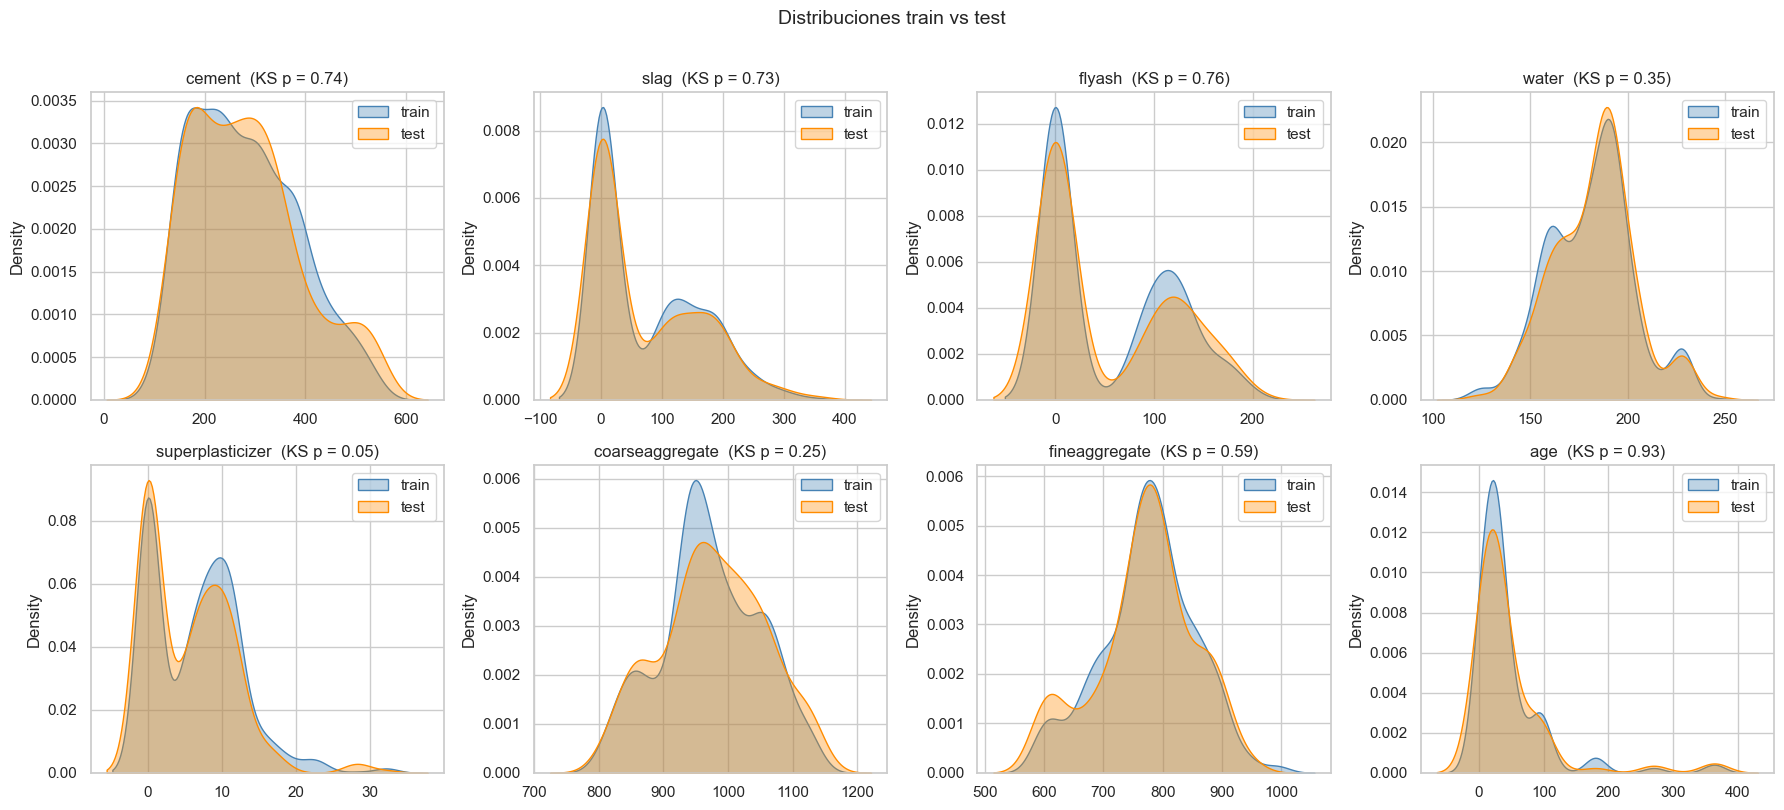

,media_train,media_test,KS_stat,p_valor
variable,,,,
cement,280.63,282.42,0.05,0.74
slag,74.74,71.93,0.05,0.73
flyash,54.87,52.59,0.04,0.76
water,181.03,182.82,0.06,0.35
superplasticizer,6.50,5.51,0.09,0.05
coarseaggregate,971.40,976.46,0.07,0.25
fineaggregate,775.13,769.97,0.05,0.59
age,44.95,47.32,0.04,0.93


In [23]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
ks_rows = []
for ax, col in zip(axes.ravel(), FEATURES):
    sns.kdeplot(train[col], ax=ax, label="train", fill=True, alpha=0.35, color="steelblue")
    sns.kdeplot(test[col], ax=ax, label="test", fill=True, alpha=0.35, color="darkorange")
    ks = stats.ks_2samp(train[col], test[col])
    ks_rows.append({"variable": col, "media_train": train[col].mean(), "media_test": test[col].mean(),
                    "KS_stat": ks.statistic, "p_valor": ks.pvalue})
    ax.set_title(f"{col}  (KS p = {ks.pvalue:.2f})")
    ax.set_xlabel("")
    ax.legend()
plt.suptitle("Distribuciones train vs test", y=1.01, fontsize=14)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/07_train_vs_test.png", dpi=120, bbox_inches="tight")
plt.show()

pd.DataFrame(ks_rows).set_index("variable")

**Observaciones:**
- Las distribuciones de `train` y `test` son **prácticamente iguales**: las medias son muy cercanas y la prueba KS no rechaza la igualdad en 7 de las 8 variables (p entre 0.25 y 0.93).
- La excepción es `superplasticizer` (p = 0.048, apenas bajo 0.05): `test` tiene algo menos de superplastificante en promedio (5.5 vs 6.5 kg/m³). La diferencia es pequeña (KS = 0.09) y el rango es el mismo (0–32.2), así que la red no tendrá que extrapolar.
- No hay *covariate shift* relevante: lo que la red aprenda en `train` debería generalizar a `test`, y la validación interna debería ser un buen indicador del puntaje en Kaggle.

### Hallazgos del EDA y decisiones de preprocesamiento

1. **Escalas muy distintas entre predictores** (de 0–32 en `superplasticizer` a 800–1150 en `coarseaggregate`) → **escalamiento obligatorio** con `StandardScaler`, ajustado **solo con el conjunto de entrenamiento**. También estandarizaremos el target y lo des-escalaremos antes de calcular métricas.
2. **`age` muy asimétrica (skew 3.3), con 14 valores y relación no lineal y saturante con la resistencia** → usar **`log1p(age)`**, que sube la correlación con el target de 0.34 a 0.56. Se mantiene como numérica, no categórica.
3. **Muchos ceros en `slag` (45 %), `flyash` (54 %) y `superplasticizer` (35 %)** → agregar **indicadores binarios de presencia** para que la red distinga "no se usa" de "poca cantidad".
4. **La relación agua/cemento (r = −0.53) es mucho más informativa que el agua sola (r = −0.30)**, y la relación agua/material cementante (`water / (cement + slag + flyash)`) lo es aún más (r = −0.63) → *feature engineering* guiado por el dominio: `water/cement`, material cementante total (`binder`) y `water/binder`. Compararemos el desempeño con y sin estas variables.
5. **Datos limpios pero con mezclas duplicadas y ruido de laboratorio** (0 faltantes, 0 categóricas, 0 outliers en el target, 26 filas repetidas y 7 mezclas con resultados distintos), con **train y test de distribuciones casi idénticas** → no se imputa ni se codifica; se **valida con K-Fold agrupando mezclas idénticas** para evitar *leakage*. Con solo 721 filas, la red necesitará regularización y early stopping.

## 2. Parte 2 — Preprocesamiento

Principio rector: **toda transformación que aprende parámetros de los datos (medias, desviaciones, mínimos, máximos) se ajusta (`fit`) solo con el conjunto de entrenamiento** y después se aplica (`transform`) a validación y test. Así evitamos *data leakage*.

### 2.1 Partición train / validación agrupada por mezcla

El EDA mostró 26 filas con predictores repetidos. Con un `train_test_split` normal, una misma mezcla podría quedar en entrenamiento y en validación a la vez: la red la "recordaría" y el error de validación saldría optimista.

Por eso asignamos un **identificador de grupo** a cada combinación única de predictores y usamos `GroupShuffleSplit` (80/20, `random_state` fijo). Todas las repeticiones de una mezcla caen del mismo lado. Conservamos los duplicados en vez de borrarlos porque son ensayos reales: aportan información sobre la variabilidad del laboratorio.

> El grupo incluye `age`: la misma receta ensayada a otra edad es otra observación legítima, no un duplicado. Así está construido también el `test` de Kaggle: 216 de sus 309 filas (70 %) usan una receta que aparece en train con otra edad. Agrupar también por receta haría la validación más pesimista que el escenario real de la competencia.

In [24]:
from sklearn.model_selection import GroupShuffleSplit

groups = train.groupby(FEATURES, sort=False).ngroup().to_numpy()
print(f"Filas: {len(train)} | mezclas únicas (grupos): {len(np.unique(groups))}")

X_full = train[FEATURES].copy()
y_full = train[TARGET].to_numpy()

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, valid_idx = next(gss.split(X_full, y_full, groups))

X_tr_raw, X_va_raw = X_full.iloc[train_idx], X_full.iloc[valid_idx]
y_tr, y_va = y_full[train_idx], y_full[valid_idx]
X_te_raw = test[FEATURES].copy()

shared = set(groups[train_idx]) & set(groups[valid_idx])
print(f"train: {len(X_tr_raw)} filas | valid: {len(X_va_raw)} filas ({len(X_va_raw) / len(X_full):.1%})")
print(f"Mezclas compartidas entre train y valid: {len(shared)}")
assert len(shared) == 0

Filas: 721 | mezclas únicas (grupos): 695
train: 576 filas | valid: 145 filas (20.1%)
Mezclas compartidas entre train y valid: 0


In [25]:
# El target debe tener una distribución similar en ambos subconjuntos.
pd.DataFrame({"train": pd.Series(y_tr).describe(), "valid": pd.Series(y_va).describe()}).T

,count,mean,std,min,25%,50%,75%,max
train,576.0,35.63,16.99,2.33,22.92,34.38,46.68,82.6
valid,145.0,38.29,17.88,6.27,24.48,34.74,50.66,79.3


**Observaciones:** 721 filas forman 695 mezclas únicas. La partición queda en 576 filas de entrenamiento y 145 de validación (20.1 %), **sin ninguna mezcla compartida**. La distribución del target es parecida en ambos subconjuntos, aunque la media de validación (38.3 MPa) es algo mayor que la de entrenamiento (35.6 MPa). Esa diferencia muestra que, con 145 filas, el resultado de una sola partición depende de qué filas caigan en validación. Por eso en la Parte 6 reportaremos **K-Fold (media ± desviación)** en lugar de confiar en un único split.

### 2.2 Valores faltantes

El EDA confirmó que no hay faltantes. Lo dejamos como verificación explícita (`assert`): si en algún momento los datos cambian, el notebook falla en vez de entrenar con `NaN`. **No se aplica ninguna estrategia de imputación.**

In [26]:
for name, df in [("train", X_tr_raw), ("valid", X_va_raw), ("test", X_te_raw)]:
    assert df.isna().sum().sum() == 0, f"Hay faltantes en {name}"
print("Sin valores faltantes en train, valid ni test -> no se imputa.")

Sin valores faltantes en train, valid ni test -> no se imputa.


### 2.3 Variables categóricas

**Las 8 variables predictoras son numéricas, así que no hay nada que codificar** (no se usa `OneHotEncoder` ni `OrdinalEncoder`).

`age` tiene solo 14 valores distintos y podría tratarse como categórica. Decidimos mantenerla **numérica** por tres razones:
1. Es una magnitud **ordenada**: la resistencia crece con la edad. El one-hot pierde ese orden.
2. El one-hot no permite **interpolar**: una edad que no aparezca en train no tendría columna.
3. Con `log1p(age)` la relación con el target ya es casi monótona (r = 0.56).

### 2.4 Transformaciones y *feature engineering*

Basados en los hallazgos del EDA, definimos variables nuevas. Todas se calculan **fila por fila**, sin usar estadísticas del dataset, así que no pueden filtrar información entre conjuntos:

| Variable | Definición | Justificación |
|---|---|---|
| `log_age` | `log1p(age)` (reemplaza a `age`) | Reduce la asimetría (3.28 → −0.05) y linealiza la curva de madurez |
| `water_cement` | `water / cement` | Ley de Abrams; r = −0.53 |
| `binder` | `cement + slag + flyash` | Material cementante total |
| `water_binder` | `water / binder` | r = −0.63, la más correlacionada con el target |
| `has_slag`, `has_flyash`, `has_sp` | Indicador `> 0` | Distinguir "no se usa" de "poca cantidad" |

Definimos tres **conjuntos de variables** para comparar en la Parte 6:
- `raw`: las 8 variables originales.
- `log_age`: las originales con `age` reemplazada por `log1p(age)`.
- `fe`: `log_age` más todas las variables derivadas.

In [27]:
BINARY_FEATURES = ["has_slag", "has_flyash", "has_sp"]

def add_features(df, feature_set="fe"):
    # Transformación fila a fila: no aprende nada de los datos, por lo que no causa leakage.
    df = df.copy()
    if feature_set == "raw":
        return df
    df["log_age"] = np.log1p(df["age"])
    df = df.drop(columns=["age"])
    if feature_set == "log_age":
        return df
    df["water_cement"] = df["water"] / df["cement"]
    df["binder"] = df["cement"] + df["slag"] + df["flyash"]
    df["water_binder"] = df["water"] / df["binder"]
    df["has_slag"] = (df["slag"] > 0).astype(float)
    df["has_flyash"] = (df["flyash"] > 0).astype(float)
    df["has_sp"] = (df["superplasticizer"] > 0).astype(float)
    return df

for fs in ["raw", "log_age", "fe"]:
    print(f"{fs:8s} -> {add_features(X_tr_raw, fs).shape[1]:2d} variables: {list(add_features(X_tr_raw, fs).columns)}")

assert (train["cement"] > 0).all() and (test["cement"] > 0).all()  # divisiones seguras

raw      ->  8 variables: ['cement', 'slag', 'flyash', 'water', 'superplasticizer', 'coarseaggregate', 'fineaggregate', 'age']
log_age  ->  8 variables: ['cement', 'slag', 'flyash', 'water', 'superplasticizer', 'coarseaggregate', 'fineaggregate', 'log_age']
fe       -> 14 variables: ['cement', 'slag', 'flyash', 'water', 'superplasticizer', 'coarseaggregate', 'fineaggregate', 'log_age', 'water_cement', 'binder', 'water_binder', 'has_slag', 'has_flyash', 'has_sp']


In [28]:
X_fe_preview = add_features(X_tr_raw, "fe")
pd.DataFrame({
    "corr_csMPa": X_fe_preview.corrwith(pd.Series(y_tr, index=X_fe_preview.index)),
    "skew": X_fe_preview.skew(),
}).sort_values("corr_csMPa", key=abs, ascending=False)

,corr_csMPa,skew
water_binder,-0.62,3.47e-01
binder,0.61,3.61e-01
log_age,0.56,-3.24e-02
water_cement,-0.54,9.69e-01
cement,0.53,5.01e-01
superplasticizer,0.40,7.45e-01
water,-0.29,7.17e-02
has_sp,0.28,-6.11e-01
has_slag,0.18,-2.67e-01
fineaggregate,-0.17,-1.98e-01


**Observaciones:** las variables derivadas son de las más informativas. `water_binder` (−0.62), `binder` (+0.61), `log_age` (+0.56) y `water_cement` (−0.54) superan en correlación a todas las variables originales salvo `cement` (+0.53). Además `log_age` queda prácticamente simétrica (skew −0.03). Que estas variables mejoren a la red, que podría aprender esas combinaciones por sí sola, lo comprobaremos en la Parte 6.

### 2.5 Escalamiento de predictores

Las redes neuronales son muy sensibles a la escala de las entradas: con variables de magnitudes tan distintas, los pesos asociados a las variables grandes dominan los gradientes y el entrenamiento se vuelve lento e inestable.

Usamos **`StandardScaler`** (media 0, desviación 1) como opción principal:
- Ninguna variable tiene cotas "naturales" que haya que respetar, y tras `log1p` no quedan colas extremas que distorsionen media y desviación.
- Deja las entradas centradas en 0, el rango donde ReLU/GELU y la inicialización por defecto de `nn.Linear` funcionan bien.
- `MinMaxScaler` queda como alternativa a comparar en la Parte 6.

Los **indicadores binarios no se escalan** (`passthrough`): ya están en {0, 1} y así conservan su interpretación.

Encapsulamos todo en un `Pipeline` de scikit-learn (`FunctionTransformer` → `ColumnTransformer`). Así el mismo objeto, ajustado una sola vez con train, transforma idénticamente valid y test.

In [29]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, FunctionTransformer

SCALERS = {"standard": StandardScaler, "minmax": MinMaxScaler}

def make_preprocessor(feature_set="fe", scaler="standard"):
    cols = add_features(X_full.head(), feature_set).columns
    num_cols = [c for c in cols if c not in BINARY_FEATURES]
    bin_cols = [c for c in cols if c in BINARY_FEATURES]
    return Pipeline([
        ("features", FunctionTransformer(add_features, kw_args={"feature_set": feature_set})),
        ("scale", ColumnTransformer(
            [("num", SCALERS[scaler](), num_cols), ("bin", "passthrough", bin_cols)],
            verbose_feature_names_out=False,
        )),
    ])

preprocessor = make_preprocessor("fe", "standard")
X_train = preprocessor.fit_transform(X_tr_raw)   # fit SOLO con train
X_valid = preprocessor.transform(X_va_raw)
X_test = preprocessor.transform(X_te_raw)
FEATURE_NAMES = list(preprocessor.named_steps["scale"].get_feature_names_out())

print("X_train:", X_train.shape, "| X_valid:", X_valid.shape, "| X_test:", X_test.shape)
preprocessor

X_train: (576, 14) | X_valid: (145, 14) | X_test: (309, 14)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('features', ...), ('scale', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function add...0023AD7F5B9C0>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=NoneDictionary of additional keyword arguments to pass to f

In [30]:
# Verificación: train queda con media 0 y desviación 1; valid y test, cerca pero no exactos.
# Si valid tuviera media 0 exacta, sería señal de que el scaler se ajustó con valid (leakage).
check = pd.DataFrame({
    "media_train": X_train.mean(axis=0), "std_train": X_train.std(axis=0),
    "media_valid": X_valid.mean(axis=0), "std_valid": X_valid.std(axis=0),
    "media_test": X_test.mean(axis=0), "std_test": X_test.std(axis=0),
}, index=FEATURE_NAMES)
check

,media_train,std_train,media_valid,std_valid,media_test,std_test
cement,7.71e-18,1.00,2.32e-01,0.97,6.40e-02,1.04
slag,5.24e-17,1.00,-1.77e-01,0.91,-6.78e-02,1.01
flyash,1.85e-17,1.00,-3.83e-02,0.94,-4.34e-02,1.02
water,5.49e-16,1.00,-9.27e-02,0.89,6.27e-02,0.94
superplasticizer,-5.55e-17,1.00,6.56e-02,1.02,-1.54e-01,0.98
coarseaggregate,9.22e-16,1.00,4.21e-02,1.01,7.47e-02,1.05
fineaggregate,-4.87e-16,1.00,2.17e-02,0.85,-5.91e-02,1.02
log_age,9.41e-17,1.00,-2.48e-03,1.01,-8.17e-03,1.03
water_cement,-3.58e-16,1.00,-2.60e-01,0.83,-4.94e-02,0.93
binder,2.22e-16,1.00,6.60e-02,0.99,-2.23e-02,1.01


**Observaciones:** en train cada variable continua queda con media 0 y desviación 1 exactas. En valid y test las medias quedan cerca de 0 (|media| ≤ 0.26) y las desviaciones cerca de 1, pero no son exactas. Eso es lo esperado cuando el scaler se ajusta **solo con train**, y confirma que no hay *leakage*. Las variables binarias conservan sus valores {0, 1}.

In [31]:
fitted_scaler = preprocessor.named_steps["scale"].named_transformers_["num"]
num_names = [c for c in FEATURE_NAMES if c not in BINARY_FEATURES]
train_means = add_features(X_tr_raw, "fe")[num_names].mean().to_numpy()
assert np.allclose(fitted_scaler.mean_, train_means), "El scaler no se ajustó solo con train"
print("OK: las medias del scaler coinciden con las de X_train -> ajustado solo con train.")

OK: las medias del scaler coinciden con las de X_train -> ajustado solo con train.


### 2.6 Escalamiento del target

Estandarizamos también `csMPa` (media ≈ 36, desviación ≈ 17). Con el target en escala ~N(0, 1), la salida lineal de la red parte cerca del valor correcto, los gradientes de la `MSELoss` tienen magnitudes razonables y el *learning rate* se vuelve menos delicado.

**Importante:** la red predice en escala estandarizada. Antes de calcular **cualquier métrica** o de generar la submission hay que **invertir la transformación** (`y_scaler.inverse_transform`), para trabajar en MPa / MPa².

In [32]:
y_scaler = StandardScaler()
y_train_s = y_scaler.fit_transform(y_tr.reshape(-1, 1))   # fit SOLO con train, forma (N, 1)
y_valid_s = y_scaler.transform(y_va.reshape(-1, 1))

print(f"y_scaler -> media = {y_scaler.mean_[0]:.2f} MPa, desviación = {y_scaler.scale_[0]:.2f} MPa")
print("y_train_s:", y_train_s.shape, "| media", y_train_s.mean().round(3), "| std", y_train_s.std().round(3))

# La inversión devuelve exactamente los valores originales.
assert np.allclose(y_scaler.inverse_transform(y_valid_s).ravel(), y_va)
print("OK: inverse_transform recupera el target en MPa.")

y_scaler -> media = 35.63 MPa, desviación = 16.98 MPa
y_train_s: (576, 1) | media 0.0 | std 1.0
OK: inverse_transform recupera el target en MPa.


### Resumen del preprocesamiento

| Paso | Decisión |
|---|---|
| Partición | 80/20 con `GroupShuffleSplit` por mezcla (sin mezclas compartidas), `random_state = 42` |
| Faltantes | Ninguno → sin imputación (verificado con `assert`) |
| Categóricas | Ninguna → sin encoding; `age` se mantiene numérica (`log1p`) |
| Feature engineering | `log_age`, `water_cement`, `binder`, `water_binder`, `has_slag`, `has_flyash`, `has_sp` (conjunto `fe`, 14 variables) |
| Escalamiento X | `StandardScaler` para continuas, binarias sin escalar; ajustado solo con train |
| Escalamiento y | `StandardScaler`, invertido antes de métricas y submission |
| Encapsulamiento | `Pipeline` + `ColumnTransformer` → misma transformación para valid y test |

La función `make_preprocessor(feature_set, scaler)` se reutiliza en la Parte 6: dentro de cada fold del K-Fold se crea y ajusta **un preprocesador nuevo**, para comparar `raw` vs `log_age` vs `fe` y `standard` vs `minmax` sin *leakage*.

## 3. Parte 3 — `Dataset` y `DataLoader`

Adaptamos la clase `MyDataset` de `02_asl.ipynb`. Los cambios para **regresión** son:

| | `MyDataset` (ASL, clasificación) | `ConcreteDataset` (regresión) |
|---|---|---|
| `x` | `float` | `float32` |
| `y` | entero (`long`), forma `(N,)` | **`float32`, forma `(N, 1)`** con `.view(-1, 1)` |
| Test | — | `y` opcional, para poder envolver `test.csv` sin target |

Con solo 721 filas, todo el dataset cabe en memoria: convertimos `X` e `y` a tensores **una sola vez** y los enviamos al `device` en el constructor, igual que en el notebook de clase.

In [33]:
class ConcreteDataset(Dataset):
    def __init__(self, x, y=None):
        self.xs = torch.tensor(x, dtype=torch.float32).to(device)
        # (N, 1): evita el broadcasting silencioso de MSELoss entre (N, 1) y (N,).
        self.ys = None if y is None else torch.tensor(y, dtype=torch.float32).view(-1, 1).to(device)

    def __getitem__(self, idx):
        if self.ys is None:
            return self.xs[idx]
        return self.xs[idx], self.ys[idx]

    def __len__(self):
        return len(self.xs)

Creamos los `DataLoader`:
- `train_loader` con `shuffle=True`, para que los mini-batches cambien en cada época. Le pasamos un `torch.Generator` con semilla para que el orden sea reproducible.
- `valid_loader` con `shuffle=False`: el orden no afecta la evaluación.

Empezamos con `BATCH_SIZE = 32`, el valor de los notebooks de clase. Con 576 filas son 18 actualizaciones por época, un equilibrio razonable entre ruido del gradiente y velocidad. En la Parte 6 probaremos 16 y 64.

In [34]:
BATCH_SIZE = 32

def make_loader(x, y=None, batch_size=BATCH_SIZE, shuffle=False, seed=SEED):
    ds = ConcreteDataset(x, y)
    gen = torch.Generator().manual_seed(seed) if shuffle else None
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, generator=gen)

train_loader = make_loader(X_train, y_train_s, shuffle=True)
valid_loader = make_loader(X_valid, y_valid_s, shuffle=False)
test_loader = make_loader(X_test)

train_N, valid_N = len(train_loader.dataset), len(valid_loader.dataset)
print(f"train_N = {train_N} ({len(train_loader)} batches) | valid_N = {valid_N} ({len(valid_loader)} batches)")

train_N = 576 (18 batches) | valid_N = 145 (5 batches)


In [35]:
xb, yb = next(iter(train_loader))
print("x batch:", tuple(xb.shape), xb.dtype, xb.device)
print("y batch:", tuple(yb.shape), yb.dtype, yb.device)
assert yb.shape == (BATCH_SIZE, 1) and yb.dtype == torch.float32

x batch: (32, 14) torch.float32 cpu
y batch: (32, 1) torch.float32 cpu


## 4. Parte 4 — Arquitectura de la red

Partimos de la estructura `nn.Sequential` de `01_mnist.ipynb` (`nn.Linear` + `nn.ReLU`) y la adaptamos a regresión:
- **Sin `nn.Flatten`**: la entrada ya es un vector de 14 variables, no una imagen.
- **Salida de 1 neurona sin activación**: el target estandarizado puede tomar cualquier valor real. Una ReLU o una sigmoide al final recortarían las predicciones.
- **Al menos 3 capas ocultas** de ancho decreciente (embudo 128 → 64 → 32).

Escribimos una función constructora, `build_mlp`, para variar en la Parte 6 la profundidad, el ancho, la activación, el Dropout y la BatchNorm sin reescribir el modelo.

In [36]:
def build_mlp(in_dim, hidden=(128, 64, 32), activation=nn.ReLU, dropout=0.0, batchnorm=False):
    layers, prev = [], in_dim
    for width in hidden:
        layers.append(nn.Linear(prev, width))
        if batchnorm:
            layers.append(nn.BatchNorm1d(width))
        layers.append(activation())
        if dropout > 0:
            layers.append(nn.Dropout(dropout))
        prev = width
    layers.append(nn.Linear(prev, 1))  # salida de regresión: 1 neurona, sin activación
    return nn.Sequential(*layers).to(device)

def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

N_FEATURES = X_train.shape[1]
set_seed()
model = build_mlp(N_FEATURES)
print(model)
print(f"\nParámetros entrenables: {count_params(model):,}")

Sequential(
  (0): Linear(in_features=14, out_features=128, bias=True)
  (1): ReLU()
  (2): Linear(in_features=128, out_features=64, bias=True)
  (3): ReLU()
  (4): Linear(in_features=64, out_features=32, bias=True)
  (5): ReLU()
  (6): Linear(in_features=32, out_features=1, bias=True)
)

Parámetros entrenables: 12,289


In [37]:
# Desglose de parámetros por capa: pesos (entrada × salida) + sesgos (salida).
pd.DataFrame(
    [(name, tuple(p.shape), p.numel()) for name, p in model.named_parameters()],
    columns=["parámetro", "forma", "n"],
)

,parámetro,forma,n
0,0.weight,"(128, 14)",1792
1,0.bias,"(128,)",128
2,2.weight,"(64, 128)",8192
3,2.bias,"(64,)",64
4,4.weight,"(32, 64)",2048
5,4.bias,"(32,)",32
6,6.weight,"(1, 32)",32
7,6.bias,"(1,)",1


In [38]:
with torch.no_grad():
    out = model(xb)
print("Salida de un batch:", tuple(out.shape))
assert out.shape == yb.shape

Salida de un batch: (32, 1)


El modelo base tiene unos 12 000 parámetros para 576 filas de entrenamiento: puede **memorizar** el conjunto de entrenamiento. Por eso son clave el **early stopping** (Parte 5) y la regularización (Dropout / weight decay, Parte 6).

> A diferencia de los notebooks de clase, **no usamos `torch.compile`**: en CPU/Windows no aporta beneficios con un modelo tan pequeño y puede fallar al compilar.

## 5. Parte 5 — Entrenamiento y validación

### 5.1 Pérdida, optimizador y métricas

- **Pérdida:** `nn.MSELoss()`. Optimiza directamente la métrica oficial de la competencia (MSE).
- **Optimizador:** `Adam`, el de los notebooks de clase. Adapta el paso por parámetro y funciona bien sin mucho ajuste.
- **Learning rate:** `1e-3`, el valor por defecto de Adam. Con entradas y target estandarizados, los gradientes tienen magnitudes del orden de 1 y este paso es estable. En 5.4 lo justificamos empíricamente comparando varios valores.

La función `get_batch_accuracy` de clasificación se reemplaza por `regression_metrics`, que calcula **MSE (métrica oficial), RMSE, MAE y R² en la escala original (MPa)**: las predicciones se des-escalan con `y_scaler.inverse_transform` antes de medir.

In [39]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def regression_metrics(y_true, y_pred):
    y_true, y_pred = np.ravel(y_true), np.ravel(y_pred)
    mse = mean_squared_error(y_true, y_pred)
    return {"MSE": mse, "RMSE": np.sqrt(mse),
            "MAE": mean_absolute_error(y_true, y_pred), "R2": r2_score(y_true, y_pred)}

def to_mpa(y_scaled, scaler):
    return scaler.inverse_transform(np.asarray(y_scaled).reshape(-1, 1)).ravel()

### 5.2 Funciones `train()` y `validate()`

Adaptadas de `01_mnist.ipynb`, con estos cambios:
- Reciben `model`, `loader`, `loss_function` y `optimizer` como **argumentos** en lugar de usar variables globales, para reutilizarlas en K-Fold.
- La pérdida se acumula **ponderada por el tamaño del batch** y se divide por `N`. Así se obtiene la pérdida media por muestra y el último batch, más pequeño, no distorsiona el promedio. Los notebooks de clase sumaban la pérdida de cada batch.
- `validate()` usa `model.eval()` + `torch.no_grad()`, y devuelve también las predicciones para calcular las métricas en MPa.

In [40]:
def train(model, loader, loss_function, optimizer):
    model.train()
    total_loss = 0.0
    for x, y in loader:
        output = model(x)
        optimizer.zero_grad()
        batch_loss = loss_function(output, y)
        batch_loss.backward()
        optimizer.step()
        total_loss += batch_loss.item() * len(x)
    return total_loss / len(loader.dataset)


def validate(model, loader, loss_function):
    model.eval()
    total_loss, preds = 0.0, []
    with torch.no_grad():
        for x, y in loader:
            output = model(x)
            total_loss += loss_function(output, y).item() * len(x)
            preds.append(output)
    return total_loss / len(loader.dataset), torch.cat(preds).cpu().numpy()


def predict(model, loader):
    model.eval()
    with torch.no_grad():
        preds = [model(batch[0] if isinstance(batch, (list, tuple)) else batch) for batch in loader]
    return torch.cat(preds).cpu().numpy()

### 5.3 Ciclo de entrenamiento con early stopping

`fit()` entrena por épocas y en cada una registra la **loss de entrenamiento y de validación** junto con las métricas de validación en MPa. Implementa **early stopping**: guarda una copia de los pesos cada vez que la loss de validación mejora y, si no mejora durante `patience` épocas seguidas, detiene el entrenamiento y **restaura el mejor modelo**.

Usamos un máximo alto de épocas (2000) y `patience = 100`. Con un dataset tan pequeño y mini-batches ruidosos, la curva de validación oscila, y una paciencia corta cortaría el entrenamiento antes de tiempo.

In [41]:
import copy
import time

def fit(model, train_loader, valid_loader, y_valid_mpa, y_scaler, lr=1e-3, weight_decay=0.0,
        epochs=2000, patience=100, verbose=0):
    loss_function = nn.MSELoss()
    optimizer = Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    history, best_loss, best_epoch, best_state, wait = [], np.inf, 0, None, 0

    for epoch in range(1, epochs + 1):
        train_loss = train(model, train_loader, loss_function, optimizer)
        valid_loss, valid_pred = validate(model, valid_loader, loss_function)
        metrics = regression_metrics(y_valid_mpa, to_mpa(valid_pred, y_scaler))
        history.append({"epoch": epoch, "train_loss": train_loss, "valid_loss": valid_loss,
                        **{f"valid_{k}": v for k, v in metrics.items()}})

        if valid_loss < best_loss - 1e-6:
            best_loss, best_epoch, wait = valid_loss, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1

        if verbose and (epoch % verbose == 0 or epoch == 1):
            print(f"Epoch {epoch:4d} | train loss {train_loss:.4f} | valid loss {valid_loss:.4f} | "
                  f"valid MSE {metrics['MSE']:7.2f} MPa² | R² {metrics['R2']:.3f}")
        if wait >= patience:
            if verbose:
                print(f"Early stopping en la época {epoch}: sin mejora en {patience} épocas.")
            break

    model.load_state_dict(best_state)
    return model, pd.DataFrame(history), best_epoch

### 5.4 Elección del learning rate

Antes de entrenar el modelo base comparamos varios *learning rates* con la misma arquitectura, la misma semilla y el mismo split. Así justificamos `1e-3` con evidencia y no solo por ser el valor por defecto.

In [42]:
lr_rows, lr_histories = [], {}
for lr in [1e-4, 3e-4, 1e-3, 3e-3, 1e-2]:
    set_seed()
    m = build_mlp(N_FEATURES)
    t0 = time.time()
    m, h, best_ep = fit(m, make_loader(X_train, y_train_s, shuffle=True), valid_loader, y_va, y_scaler, lr=lr)
    best = h.loc[h["epoch"] == best_ep].iloc[0]
    lr_rows.append({"lr": lr, "mejor_época": best_ep, "épocas_totales": len(h),
                    "valid_MSE": best["valid_MSE"], "valid_RMSE": best["valid_RMSE"],
                    "valid_R2": best["valid_R2"], "segundos": time.time() - t0})
    lr_histories[lr] = h

lr_results = pd.DataFrame(lr_rows).set_index("lr")
lr_results

,mejor_época,épocas_totales,valid_MSE,valid_RMSE,valid_R2,segundos
lr,,,,,,
1.00e-04,283,383,17.37,4.17,0.95,38.05
3.00e-04,153,253,17.18,4.14,0.95,28.56
1.00e-03,88,188,16.63,4.08,0.95,17.36
3.00e-03,279,379,16.01,4.00,0.95,28.53
1.00e-02,196,296,15.46,3.93,0.95,22.29


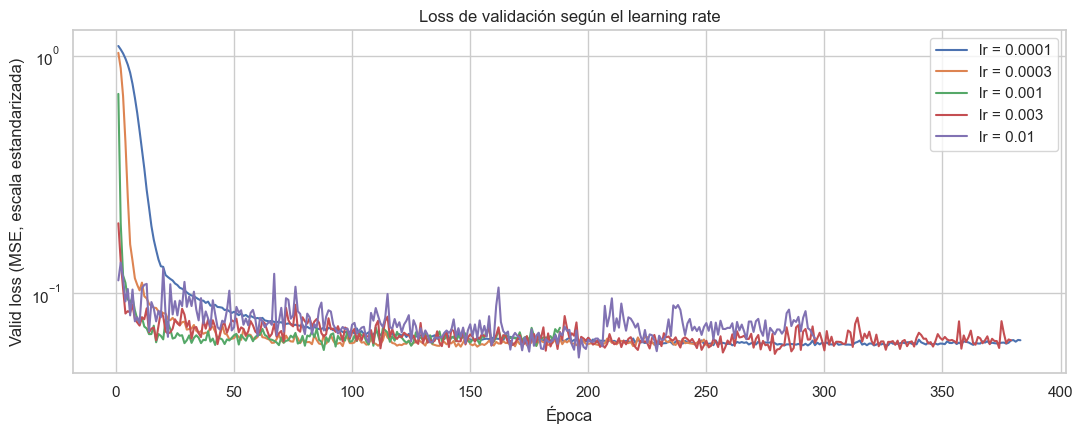

In [43]:
fig, ax = plt.subplots(figsize=(11, 4.5))
for lr, h in lr_histories.items():
    ax.plot(h["epoch"], h["valid_loss"], label=f"lr = {lr:g}")
ax.set(yscale="log", xlabel="Época", ylabel="Valid loss (MSE, escala estandarizada)",
       title="Loss de validación según el learning rate")
ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/08_lr_comparison.png", dpi=120, bbox_inches="tight")
plt.show()

**Observaciones sobre el learning rate:**
- Todos los valores probados convergen a un MSE de validación muy parecido (**15.5–17.4 MPa²**, R² ≈ 0.95). Entre el mejor y el peor hay unos 2 MPa², una diferencia del orden del ruido de cambiar la semilla o el split. Con un único split no se puede afirmar que uno sea mejor.
- Lo que sí cambia es la **dinámica**: con `1e-4` la red tarda unas 20 épocas en bajar de la loss inicial y unas 280 en alcanzar su mejor punto. Con `1e-2` la curva es la más ruidosa, con picos frecuentes, porque el paso es tan grande que el optimizador "rebota" alrededor del mínimo.
- **Elegimos `lr = 1e-3`**: es el que llega antes a su mejor punto (época 88, ~17 s), su curva es estable y su MSE está dentro del rango de los demás. `3e-3` y `1e-2` vuelven a compararse en la Parte 6 con K-Fold, donde el promedio sobre 5 folds sí permite distinguir diferencias pequeñas.

### 5.5 Entrenamiento del modelo base

In [44]:
LR = 1e-3

set_seed()
model = build_mlp(N_FEATURES)
train_loader = make_loader(X_train, y_train_s, shuffle=True)

t0 = time.time()
model, history, best_epoch = fit(model, train_loader, valid_loader, y_va, y_scaler, lr=LR, verbose=100)
print(f"\nMejor época: {best_epoch} | tiempo: {time.time() - t0:.1f} s")

Epoch    1 | train loss 0.8394 | valid loss 0.6932 | valid MSE  199.81 MPa² | R² 0.371


Epoch  100 | train loss 0.0198 | valid loss 0.0629 | valid MSE   18.12 MPa² | R² 0.943


Early stopping en la época 188: sin mejora en 100 épocas.

Mejor época: 88 | tiempo: 16.0 s


### 5.6 Curvas de aprendizaje

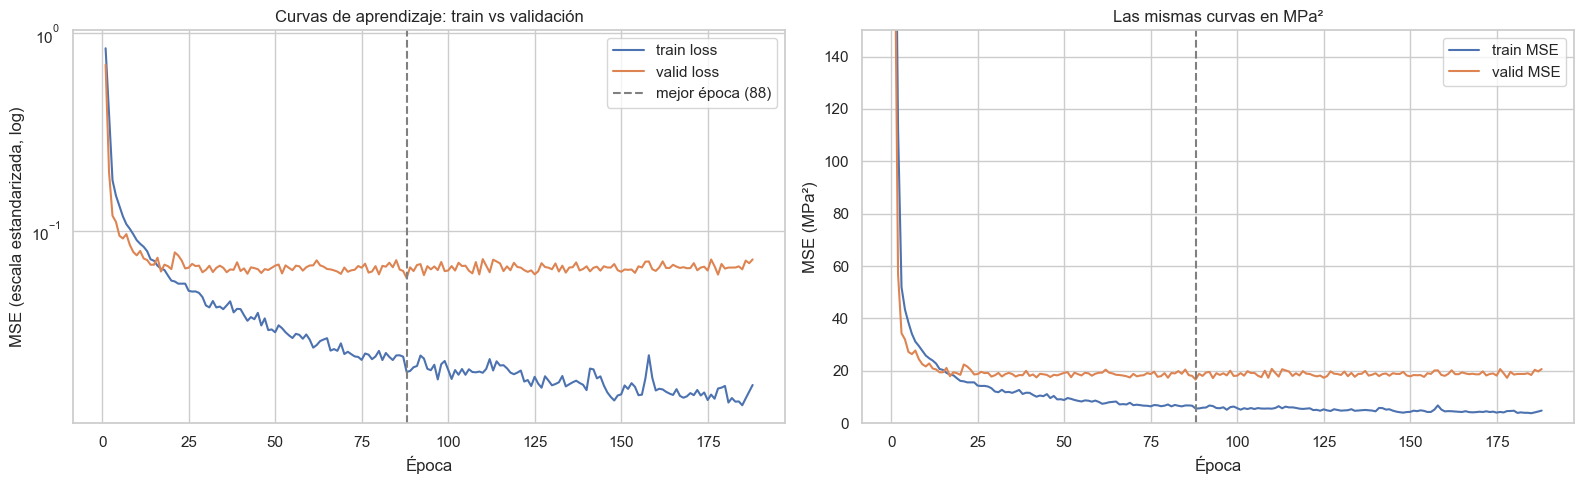

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(history["epoch"], history["train_loss"], label="train loss")
axes[0].plot(history["epoch"], history["valid_loss"], label="valid loss")
axes[0].axvline(best_epoch, color="gray", ls="--", label=f"mejor época ({best_epoch})")
axes[0].set(yscale="log", xlabel="Época", ylabel="MSE (escala estandarizada, log)",
            title="Curvas de aprendizaje: train vs validación")
axes[0].legend()

y_var = y_scaler.scale_[0] ** 2
axes[1].plot(history["epoch"], history["train_loss"] * y_var, label="train MSE")
axes[1].plot(history["epoch"], history["valid_MSE"], label="valid MSE")
axes[1].axvline(best_epoch, color="gray", ls="--")
axes[1].set(ylim=(0, 150), xlabel="Época", ylabel="MSE (MPa²)", title="Las mismas curvas en MPa²")
axes[1].legend()

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/09_learning_curves.png", dpi=120, bbox_inches="tight")
plt.show()

**Discusión: ¿underfitting u overfitting?**
- **No hay underfitting:** en ~20 épocas ambas losses caen más de un orden de magnitud, y el MSE de validación baja de ~200 MPa² a ~20 MPa². La red tiene capacidad de sobra para el problema.
- **Hay overfitting moderado a partir de la época ~20:** la loss de **train sigue bajando** de forma sostenida (hasta ~4 MPa²), mientras que la de **validación se estanca** en ~17–20 MPa² y oscila. La brecha entre ambas crece época a época: la red empieza a memorizar el ruido de laboratorio (el EDA mostró que una misma mezcla puede dar resultados que difieren varios MPa) en lugar de aprender patrones generalizables.
- La validación no empeora drásticamente: se queda en una meseta, en lugar de la clásica "U". El early stopping elige la época 88 por ser el mínimo puntual de esa meseta, y detiene el entrenamiento en la 188 tras 100 épocas sin mejora.
- **Conclusión:** el early stopping evita el deterioro, pero la brecha train/valid (≈ 5 vs ≈ 17 MPa²) sugiere probar **regularización** (Dropout, weight decay) y redes más pequeñas en la Parte 6.

### 5.7 Métricas del mejor modelo (en MPa)

Evaluamos el modelo restaurado (mejor época) en train y validación con `model.eval()`. La loss de entrenamiento registrada durante las épocas se calcula mientras los pesos cambian; esta evaluación es sobre los pesos finales.

In [46]:
pred_train = to_mpa(predict(model, make_loader(X_train, y_train_s)), y_scaler)
pred_valid = to_mpa(predict(model, valid_loader), y_scaler)

base_metrics = pd.DataFrame({
    "train": regression_metrics(y_tr, pred_train),
    "valid": regression_metrics(y_va, pred_valid),
}).T
base_metrics

,MSE,RMSE,MAE,R2
train,5.28,2.30,1.54,0.98
valid,16.63,4.08,3.05,0.95


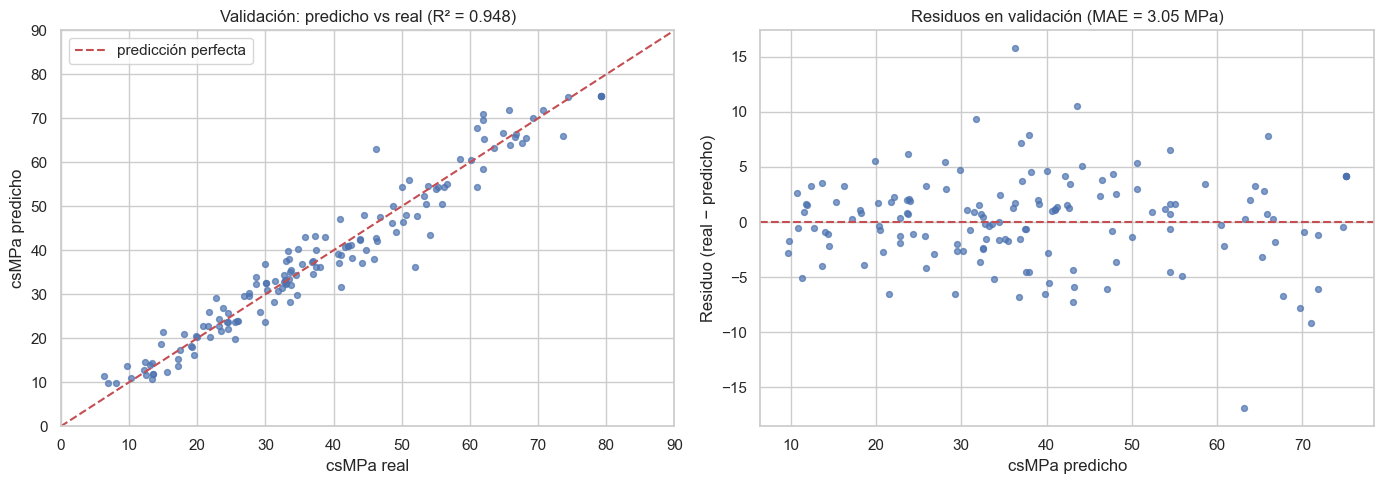

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
lims = [0, 90]
axes[0].scatter(y_va, pred_valid, s=18, alpha=0.7)
axes[0].plot(lims, lims, "r--", label="predicción perfecta")
axes[0].set(xlim=lims, ylim=lims, xlabel="csMPa real", ylabel="csMPa predicho",
            title=f"Validación: predicho vs real (R² = {base_metrics.loc['valid', 'R2']:.3f})")
axes[0].legend()

residuals = y_va - pred_valid
axes[1].scatter(pred_valid, residuals, s=18, alpha=0.7)
axes[1].axhline(0, color="r", ls="--")
axes[1].set(xlabel="csMPa predicho", ylabel="Residuo (real − predicho)",
            title=f"Residuos en validación (MAE = {base_metrics.loc['valid', 'MAE']:.2f} MPa)")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/10_pred_vs_real.png", dpi=120, bbox_inches="tight")
plt.show()

**Resultados del modelo base** (MLP 14 → 128 → 64 → 32 → 1, ReLU, Adam `lr = 1e-3`, batch 32, early stopping):

| Conjunto | MSE (MPa²) | RMSE (MPa) | MAE (MPa) | R² |
|---|---|---|---|---|
| Train | 5.28 | 2.30 | 1.54 | 0.982 |
| **Validación** | **16.63** | **4.08** | **3.05** | **0.948** |

- La red explica el **~95 % de la varianza** de la resistencia en datos no vistos, con un error típico de ~4 MPa sobre un rango de 2–83 MPa.
- En el gráfico predicho vs real los puntos se agrupan alrededor de la diagonal en todo el rango. No hay sesgo sistemático para resistencias bajas o altas.
- Los residuos están centrados en 0 y sin patrones claros (no forman curva ni embudo), así que el modelo captura bien la no linealidad. Hay unos pocos residuos grandes (±15 MPa), compatibles con el ruido de ensayo de mezclas repetidas que vimos en el EDA.
- El MSE de train (5.3) es unas 3 veces el de validación (16.6): confirma el sobreajuste moderado discutido arriba.
- Este resultado proviene de **un solo split** de 145 filas. En la Parte 6 lo contrastamos con K-Fold y con baselines.